# RTENSO2026 2015/16 El Nino: teleconnections and equatorial evolution

Case-study companion to ESP-Lab `3b_sst_telecon.ipynb`. For the peak season:

* **Observed climatological teleconnection**: regression of 1981-2010 DJF anomalies on
  DJF Nino3.4 (per degC).
* **Event teleconnection**: the DJF 2015/16 anomaly divided by that season's Nino3.4
  anomaly, for observations and for each forecast's ensemble mean.
* **Inter-member regression**: regression of member DJF anomalies on member Nino3.4,
  pooling RTENSO2026 `clim` and `obs` members per start (20 members; noisy).
* Pattern correlations of the forecast patterns against both observed patterns.

The second part shows equatorial (5S-5N) Hovmollers of SST and 850-hPa zonal-wind
anomalies for each start.

In [15]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.colors import BoundaryNorm
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import rtenso_case as rc


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:


def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]

def map_cmap(name, ci, cmin, cmax):
    if name == "blue2red":
        cmap = mycolors.blue2red_cmap(np.arange(cmin, cmax + ci, ci))
    else:
        cmap = plt.get_cmap(name)
    return cmap


def draw_map(fig, da, nrow, ncol, index, title, field, scale=1.0):
    # Robinson map in the ESP-Lab style; NaN (e.g. land for SST) is drawn light grey.
    ci, cmin, cmax, cmap = MAP_STYLE[field]
    ci, cmin, cmax = ci * scale, cmin * scale, cmax * scale
    levels = np.arange(cmin, cmax + ci / 2, ci)
    cmap = map_cmap(cmap, ci, cmin, cmax)
    norm = BoundaryNorm(levels, ncolors=cmap.N)
    values, lon = add_cyclic_point(da.values, coord=da["lon"].values)
    values = np.ma.filled(values, np.nan)  # cartopy wraps pcolormesh only with transparent missing values
    ax = fig.add_subplot(nrow, ncol, index, projection=ccrs.Robinson(central_longitude=180))
    ax.set_facecolor("0.85")  # missing values (e.g. land for SST) show as light grey
    cntr = ax.pcolormesh(lon, da["lat"].values, values, cmap=cmap, norm=norm,
                         shading="nearest", rasterized=True, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.5)
    ax.set_global()
    ax.set_title(title, fontsize=10)
    return ax, cntr

### Run controls

In [17]:
derivation_mode = "auto"
CLIM_METHOD = "lead_drift"         # Feb/Aug drift correction: "lead_drift" or "target_month"

FIELD = "PSL"                     # PRECT, TREFHT, PSL
INDEX = "Nino3.4"
INIT_MONTHS = [2, 5, 8, 11]
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

MAP_STYLE = {
    # field: (contour interval, min, max, colormap)
    "TS": (0.25, -3.0, 3.0, "blue2red"),
    "TREFHT": (0.25, -3.0, 3.0, "blue2red"),
    "PRECT": (0.5, -5.0, 5.0, "BrBG"),
    "PSL": (0.5, -6.0, 6.0, "blue2red"),
    "U850": (0.5, -6.0, 6.0, "blue2red"),
}

# Hindcast year and cases. Each case reads
# <post_root>/<case_prefix>_<CASE_YEAR><MM>0100/ENxx/post/... (rc.post_root: RTENSO2026/post_process
# for RTENSO2026 cases, raw_model_root otherwise); "source" names
# the cached files, "init_months" the starts the case has.
CASE_YEAR = 2015
MODEL_PREFIX = "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5"
CASES = {
    "Reanalysis-CLIM": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_clim",
        "source": "RTENSO2026_clim",
        "init_months": (2, 5, 8, 11),
        "color": "tab:blue",
    },
    "Reanalysis-OBS": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs",
        "source": "RTENSO2026_obs",
        "init_months": (2, 5, 8, 11),
        "color": "tab:orange",
    },
    # Placeholder: obs ICs with NSIDCv6 sea ice; set init_months once the runs are post-processed.
    "Reanalysis-NSIDC": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs_ice_nsidc",
        "source": "RTENSO2026_obs_ice_nsidc",
        "init_months": (),
        "color": "tab:red",
    },
    "Reanalysis-FOSIRL": {
        "case_prefix": f"{MODEL_PREFIX}_BruteForce",
        "source": "Reanalysis",
        "init_months": (2, 5, 8, 11),
        "color": "tab:green",
    },
}
CASES = {name: case for name, case in CASES.items() if case["init_months"]}   # drop placeholders
DJF = [(2015, 12), (2016, 1), (2016, 2)]
REG_YEARS = (1982, 2010)            # DJF seasons (Dec of the previous year) for the observed regression
TELE_REGIONS = ["Tropics", "NorthAmerica", "Global"]
HOV_FIELDS = ["TS", "U850"]
HOV_LAT = (-5.0, 5.0)
HOV_LON = (120.0, 280.0)

OUTDIR = rc.diag_dir("RTENSO2026", "case_study", "teleconnection")
OUTDIR.mkdir(parents=True, exist_ok=True)

### Observed climatological and event teleconnections

In [18]:
%%time
def djf_series(da, years):
    seasons = [rc.obs_target_mean(da, [(y - 1, 12), (y, 1), (y, 2)]) for y in range(years[0], years[1] + 1)]
    return xr.concat(seasons, dim="year").assign_coords(year=np.arange(years[0], years[1] + 1))


def regress(field_anom, index_anom, dim):
    x = index_anom - index_anom.mean(dim)
    y = field_anom - field_anom.mean(dim)
    return (x * y).sum(dim) / (x**2).sum(dim)


obs_long = rc.obs_anomaly(FIELD, years=(rc.CLIM_YEARS[0], CASE_YEAR + 2), mode=derivation_mode)
obs_ts_long = rc.obs_anomaly("TS", years=(rc.CLIM_YEARS[0], CASE_YEAR + 2), mode=derivation_mode)
obs_nino = rc.box_mean(obs_ts_long, rc.NINO_REGIONS[INDEX])

obs_reg = regress(djf_series(obs_long, REG_YEARS), djf_series(obs_nino, REG_YEARS), "year")
obs_event_nino = float(rc.obs_target_mean(obs_nino, DJF))
obs_event = rc.obs_target_mean(obs_long, DJF) / obs_event_nino
print(f"observed DJF 2015/16 {INDEX}: {obs_event_nino:.2f} C")

observed DJF 2015/16 Nino3.4: 2.50 C
CPU times: user 175 ms, sys: 314 ms, total: 489 ms
Wall time: 740 ms


### Forecast event teleconnections and inter-member regressions

In [19]:
%%time
event, member_reg, nino_djf = {}, {}, {}
for init in INIT_MONTHS:
    pooled_field, pooled_nino = [], []
    for case in CASES:
        if init not in CASES[case]["init_months"]:
            continue
        anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, FIELD, year=CASE_YEAR, method=CLIM_METHOD, mode=derivation_mode)
        ts = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, "TS", year=CASE_YEAR, method=CLIM_METHOD, mode=derivation_mode)
        if anom is None or ts is None:
            continue
        f_djf = rc.target_mean(anom, DJF)
        n_djf = rc.target_mean(rc.box_mean(ts, rc.NINO_REGIONS[INDEX]), DJF)
        if f_djf is None:
            continue
        nino_djf[(case, init)] = n_djf.load()
        event[(case, init)] = (f_djf.mean("member") / n_djf.mean("member")).load()
        if case.startswith("RTENSO2026"):
            pooled_field.append(f_djf.assign_coords(member=[f"{case}:{m}" for m in f_djf["member"].values]))
            pooled_nino.append(n_djf.assign_coords(member=[f"{case}:{m}" for m in n_djf["member"].values]))
        print(f"[{case} init{init:02d}] DJF {INDEX} ensemble mean {float(n_djf.mean()):.2f} C (members {float(n_djf.min()):.2f} to {float(n_djf.max()):.2f})")
    if pooled_field:
        f_all, n_all = xr.concat(pooled_field, "member"), xr.concat(pooled_nino, "member")
        member_reg[init] = regress(f_all, n_all, "member").load()

[Reanalysis-CLIM init02] DJF Nino3.4 ensemble mean 1.87 C (members 0.37 to 2.99)
[Reanalysis-OBS init02] DJF Nino3.4 ensemble mean 2.04 C (members 0.51 to 3.29)
[Reanalysis-FOSIRL init02] DJF Nino3.4 ensemble mean 1.35 C (members -0.31 to 2.84)
[Reanalysis-CLIM init05] DJF Nino3.4 ensemble mean 3.15 C (members 1.98 to 3.90)
[Reanalysis-OBS init05] DJF Nino3.4 ensemble mean 3.12 C (members 2.24 to 3.66)
[Reanalysis-FOSIRL init05] DJF Nino3.4 ensemble mean 3.07 C (members 1.54 to 3.69)
[Reanalysis-CLIM init08] DJF Nino3.4 ensemble mean 2.89 C (members 2.41 to 3.58)
[Reanalysis-OBS init08] DJF Nino3.4 ensemble mean 3.08 C (members 2.00 to 3.92)
[Reanalysis-FOSIRL init08] DJF Nino3.4 ensemble mean 3.28 C (members 2.48 to 3.90)
[Reanalysis-CLIM init11] DJF Nino3.4 ensemble mean 2.50 C (members 2.14 to 2.77)
[Reanalysis-OBS init11] DJF Nino3.4 ensemble mean 2.53 C (members 1.92 to 2.92)
[Reanalysis-FOSIRL init11] DJF Nino3.4 ensemble mean 2.52 C (members 2.34 to 2.76)
CPU times: user 4.69 s,

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_teleconnection_rtenso2026_nino34_psl_djf2015_16.png


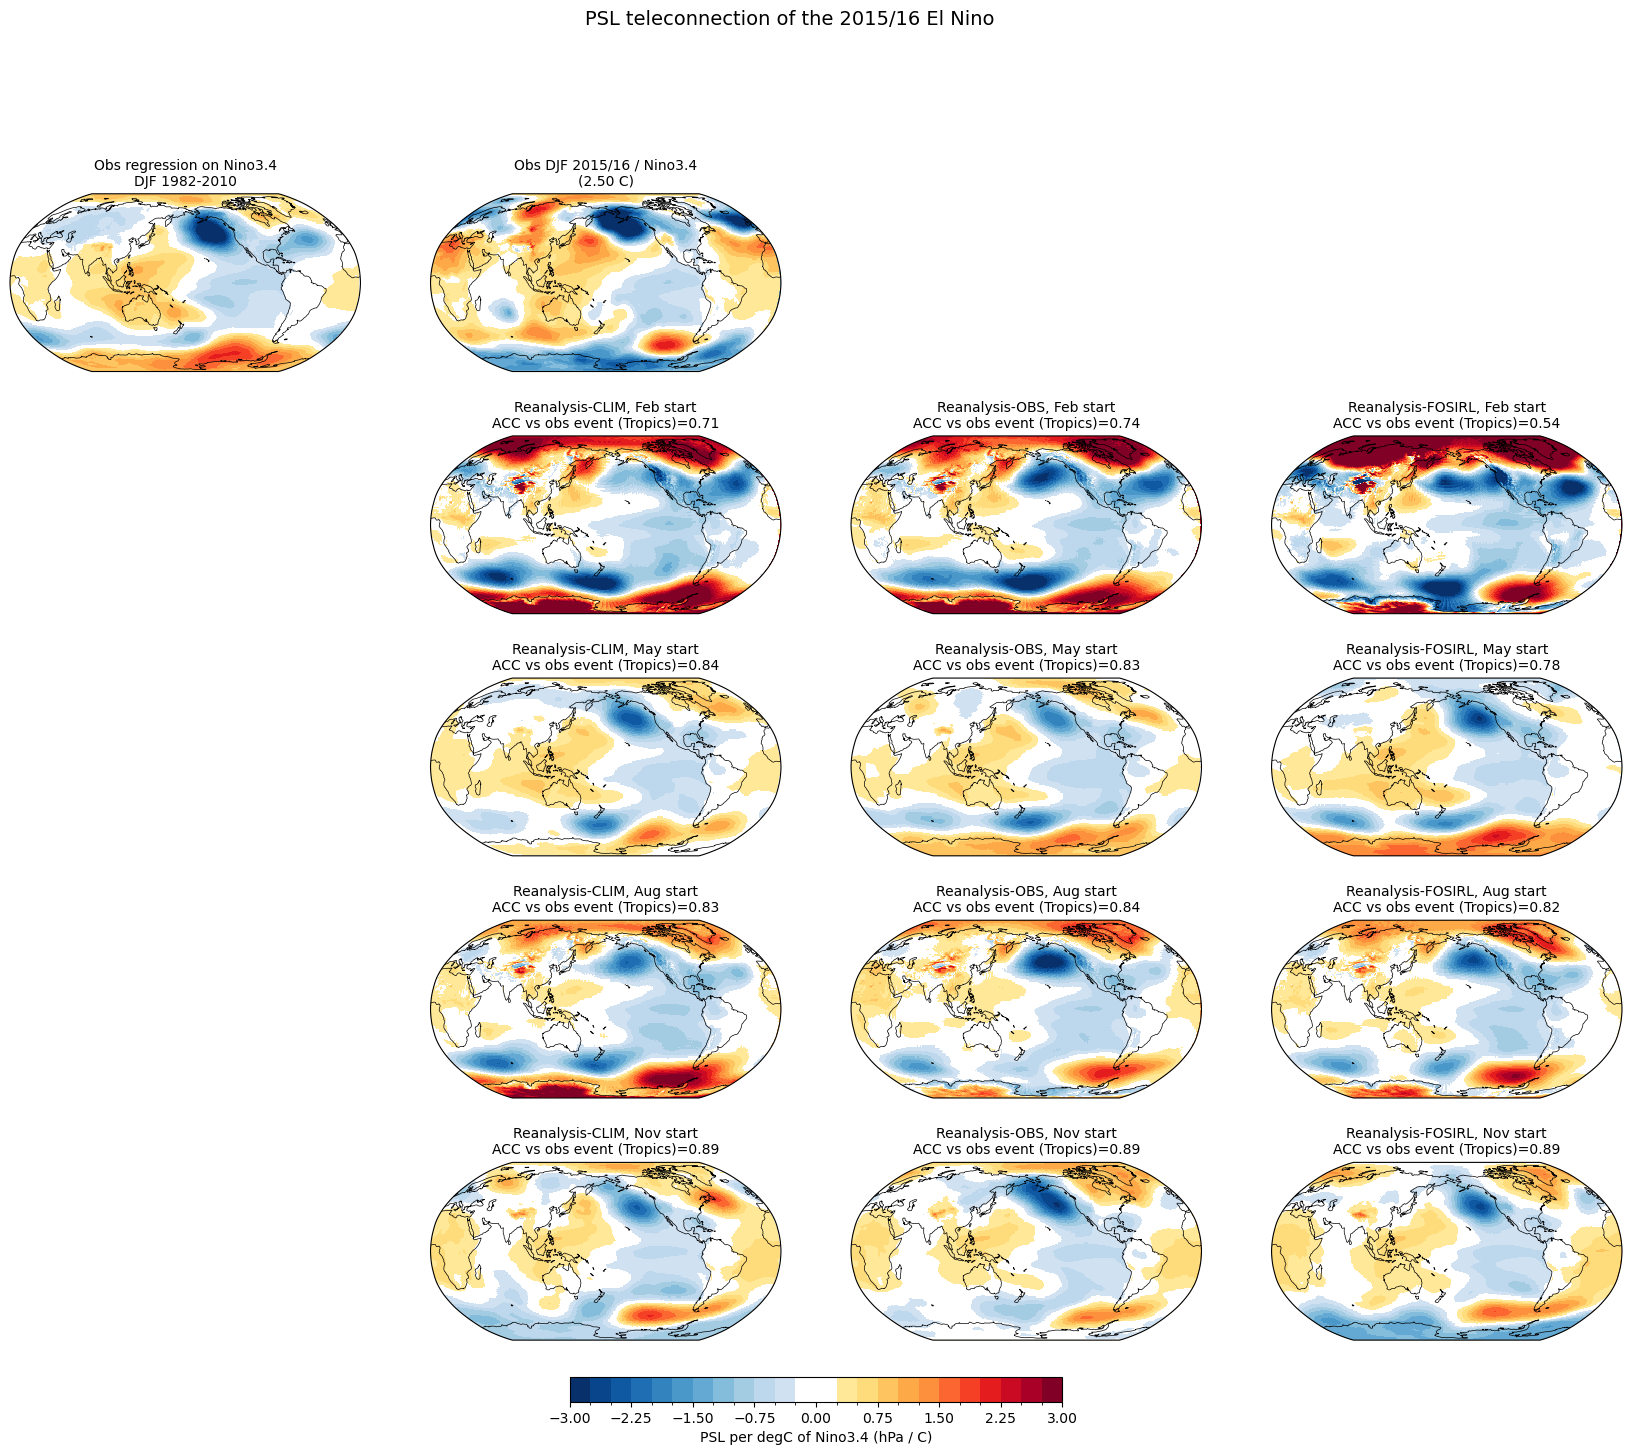

,case,start,Nino34_DJF,ACC_event_Tropics,ACC_event_NorthAmerica,ACC_event_Global,ACC_obsreg_Tropics,ACC_obsreg_NorthAmerica,ACC_obsreg_Global
0,Reanalysis-CLIM,Feb,1.87,0.712,0.020,0.166,0.778,0.530,0.472
1,Reanalysis-OBS,Feb,2.04,0.736,0.272,0.262,0.799,0.757,0.592
2,Reanalysis-FOSIRL,Feb,1.35,0.542,-0.182,0.013,0.638,0.441,0.396
3,Reanalysis-CLIM,May,3.15,0.840,0.523,0.476,0.965,0.918,0.831
4,Reanalysis-OBS,May,3.12,0.827,0.485,0.437,0.958,0.867,0.732
5,Reanalysis-FOSIRL,May,3.07,0.781,0.593,0.483,0.955,0.888,0.831
6,Reanalysis-CLIM,Aug,2.89,0.828,0.293,0.301,0.876,0.788,0.648
7,Reanalysis-OBS,Aug,3.08,0.837,0.350,0.450,0.850,0.867,0.734
8,Reanalysis-FOSIRL,Aug,3.28,0.820,0.323,0.417,0.884,0.811,0.730
9,Reanalysis-CLIM,Nov,2.50,0.893,0.316,0.519,0.878,0.696,0.663


In [20]:
scale = {"PRECT": 0.5, "TREFHT": 0.5, "PSL": 0.5}.get(FIELD, 1.0)   # per-degC colour range
ncol = 1 + len(CASES)
nrow = 1 + len(INIT_MONTHS)
fig = plt.figure(figsize=(5.2 * ncol, 3.2 * nrow))
ax, cntr = draw_map(fig, obs_reg, nrow, ncol, 1, f"Obs regression on {INDEX}\nDJF {REG_YEARS[0]}-{REG_YEARS[1]}", FIELD, scale)
draw_map(fig, obs_event, nrow, ncol, 2, f"Obs DJF 2015/16 / {INDEX}\n({obs_event_nino:.2f} C)", FIELD, scale)
rows = []
for r, init in enumerate(INIT_MONTHS, start=1):
    if init in member_reg:
        acc = float(rc.pattern_acc(member_reg[init], obs_reg, "Tropics"))
        draw_map(fig, member_reg[init], nrow, ncol, r * ncol + 1,
                 f"Member regression, {MONTH_NAMES[init]} start\nACC vs obs reg (Tropics)={acc:.2f}", FIELD, scale)
    for c, case in enumerate(CASES, start=1):
        if (case, init) not in event:
            continue
        pattern = event[(case, init)]
        acc_event = float(rc.pattern_acc(pattern, obs_event, "Tropics"))
        draw_map(fig, pattern, nrow, ncol, r * ncol + c + 1,
                 f"{case}, {MONTH_NAMES[init]} start\nACC vs obs event (Tropics)={acc_event:.2f}", FIELD, scale)
        rows.append({"case": case, "start": MONTH_NAMES[init],
                     "Nino34_DJF": round(float(nino_djf[(case, init)].mean()), 2),
                     **{f"ACC_event_{reg}": round(float(rc.pattern_acc(pattern, obs_event, reg)), 3) for reg in TELE_REGIONS},
                     **{f"ACC_obsreg_{reg}": round(float(rc.pattern_acc(pattern, obs_reg, reg)), 3) for reg in TELE_REGIONS}})
cbar = fig.colorbar(cntr, ax=fig.axes, orientation="horizontal", fraction=0.02, pad=0.03, shrink=0.6)
cbar.set_label(f"{FIELD} per degC of {INDEX} ({rc.FIELDS[FIELD]['units']} / C)")
fig.suptitle(f"{FIELD} teleconnection of the 2015/16 El Nino", fontsize=14)
print(rc.save_figure(fig, "teleconnection", "rtenso2026", INDEX.replace(".", ""), FIELD, "DJF2015-16"))
plt.show()

tele_table = pd.DataFrame(rows)
tele_table.to_csv(OUTDIR / f"RTENSO2026_case_{INDEX.replace('.', '')}_{FIELD}_teleconnection_acc.csv", index=False)
tele_table

### Equatorial Hovmollers

Mean over 5S-5N; anomalies as above. One figure per field, one row per start.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_hovmoller_ts.png


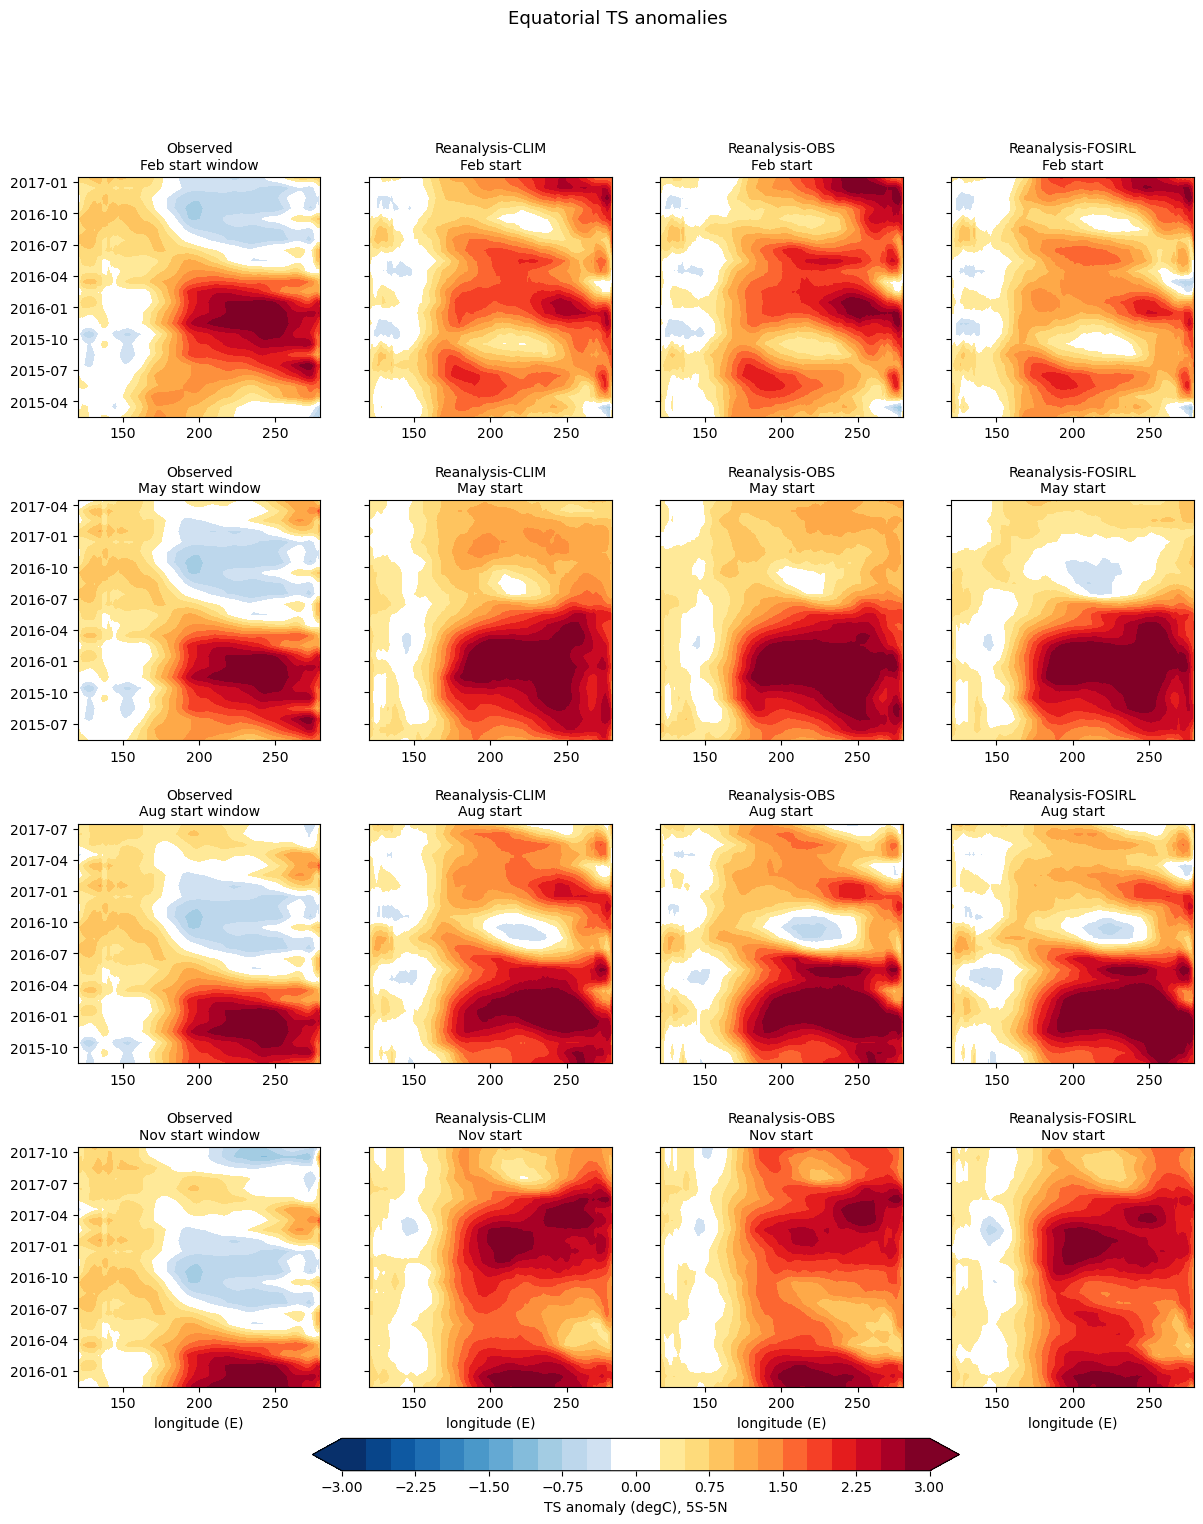

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_hovmoller_u850.png


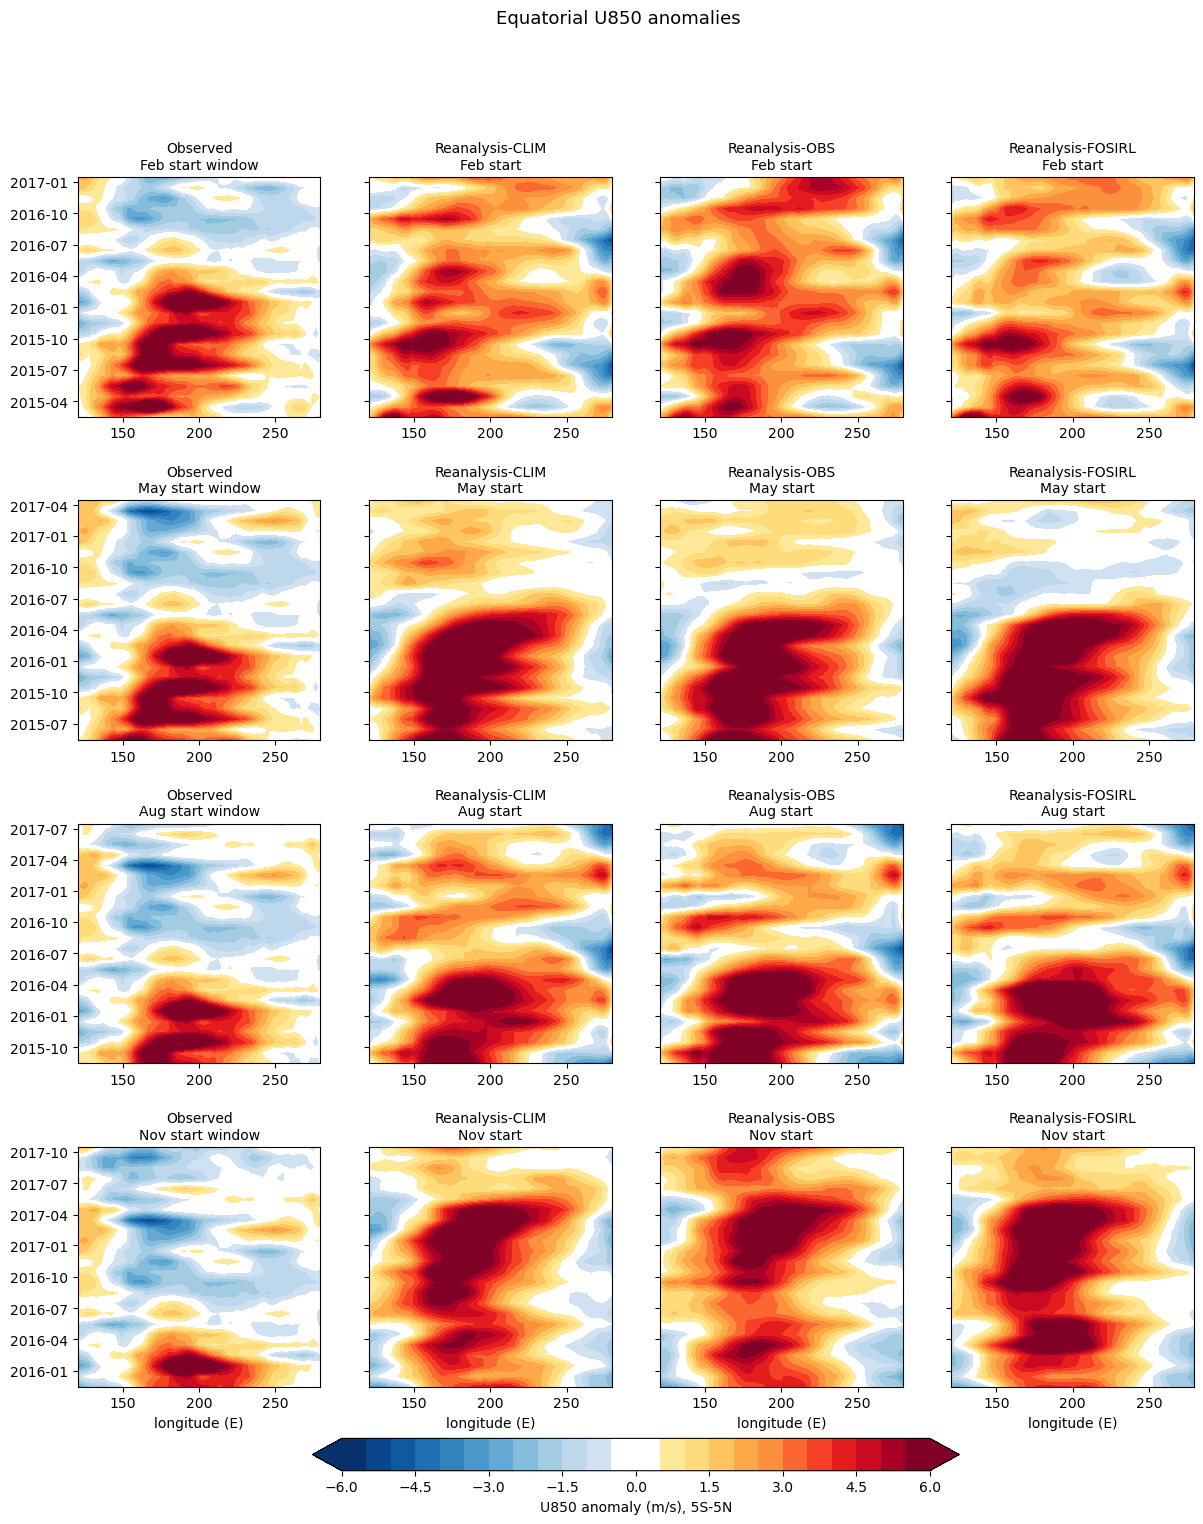

CPU times: user 11.4 s, sys: 7.82 s, total: 19.2 s
Wall time: 54.4 s


In [21]:
%%time
HOV_STYLE = {"TS": (0.25, -3.0, 3.0), "U850": (0.5, -6.0, 6.0)}


def equatorial(da):
    return rc.region_subset(da, [HOV_LON[0], HOV_LON[1], HOV_LAT[0], HOV_LAT[1]]).weighted(
        rc.area_weights(rc.region_subset(da, [HOV_LON[0], HOV_LON[1], HOV_LAT[0], HOV_LAT[1]])["lat"])).mean("lat")


for hfield in HOV_FIELDS:
    obs_h = equatorial(rc.obs_anomaly(hfield, mode=derivation_mode)).load()
    ci, vmin, vmax = HOV_STYLE[hfield]
    levels = np.arange(vmin, vmax + ci, ci)
    cmap = mycolors.blue2red_cmap(levels)
    panels = ["Observed"] + list(CASES)
    fig, axes = plt.subplots(len(INIT_MONTHS), len(panels), figsize=(3.6 * len(panels), 4.2 * len(INIT_MONTHS)), sharey="row", squeeze=False)
    for row, init in enumerate(INIT_MONTHS):
        times = None
        for col, name in enumerate(panels):
            ax = axes[row, col]
            if name == "Observed":
                continue
            if init not in CASES[name]["init_months"]:
                ax.set_visible(False)
                continue
            anom = rc.hindcast_anomaly(CASES[name]["case_prefix"], init, hfield, year=CASE_YEAR, method=CLIM_METHOD, mode=derivation_mode)
            if anom is None:
                ax.set_visible(False)
                continue
            h = equatorial(anom.mean("member")).load()
            times = h["time"].values
            cf = ax.contourf(h["lon"], to_datetime(times), h.transpose("lead", "lon"), levels=levels, cmap=cmap, extend="both")
            ax.set_title(f"{name}\n{MONTH_NAMES[init]} start", fontsize=10)
        if times is not None:
            ax = axes[row, 0]
            o = rc.match_obs(xr.DataArray(np.zeros(len(times)), dims="lead", coords={"lead": np.arange(len(times)), "time": ("lead", times)}), obs_h)
            ax.contourf(o["lon"], to_datetime(times), o.transpose("lead", "lon"), levels=levels, cmap=cmap, extend="both")
            ax.set_title(f"Observed\n{MONTH_NAMES[init]} start window", fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("longitude (E)")
    fig.subplots_adjust(hspace=0.35)
    fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.025, pad=0.04, shrink=0.6,
                 label=f"{hfield} anomaly ({rc.FIELDS[hfield]['units']}), {abs(HOV_LAT[0]):.0f}S-{HOV_LAT[1]:.0f}N")
    fig.suptitle(f"Equatorial {hfield} anomalies", fontsize=13)
    print(rc.save_figure(fig, "rtenso2026", "hovmoller", hfield))
    plt.show()